# Milestone 1 results

Displays what `grapheme_extraction/evaluate.py` wrote to `reports/`. Run that first. **All numbers are on synthetic seals.**

In [1]:
import json
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

R = Path('../reports/milestone_1')
res = json.loads((R / 'eval_results.json').read_text())

## Training curves

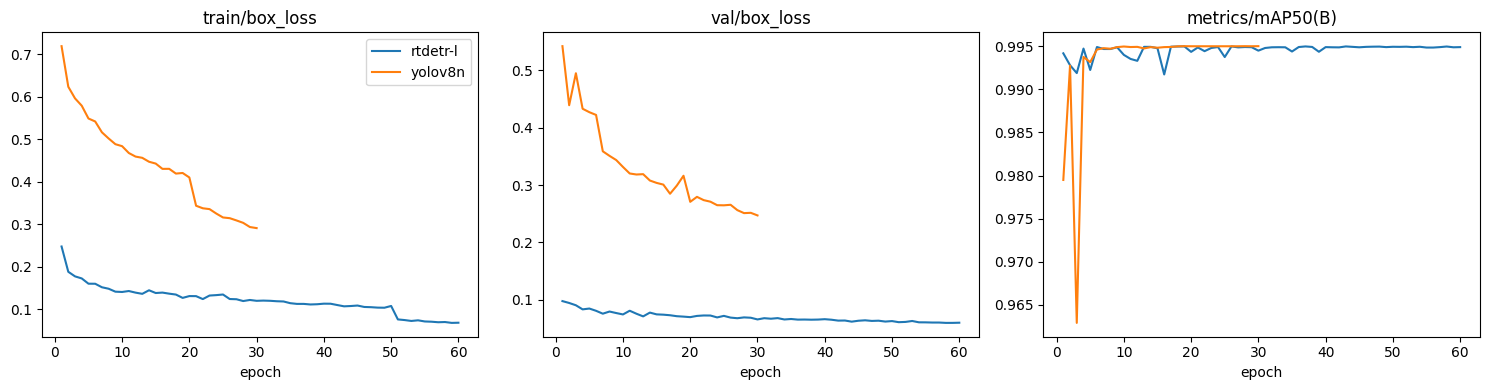

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for f in sorted(R.glob('*_results.csv')):
    df = pd.read_csv(f); df.columns = df.columns.str.strip()
    name = f.name.replace('_results.csv', '')
    for ax, col in zip(axes, ['train/box_loss', 'val/box_loss', 'metrics/mAP50(B)']):
        col = col if col in df else col.replace('box_loss', 'giou_loss')  # RT-DETR names its box loss differently
        ax.plot(df['epoch'], df[col], label=name); ax.set_title(col); ax.set_xlabel('epoch')
axes[0].legend(); plt.tight_layout()

## Detector comparison on the held-out synthetic test split (point estimate, 95% bootstrap interval)

In [3]:
pd.DataFrame({d: {m: f'{v[0]:.3f} [{v[1]:.3f}, {v[2]:.3f}]' for m, v in e['metrics'].items()} | {k: f'{v:.3f}' for k, v in e.get('ap', {}).items()}
              for d, e in res['detectors'].items()})

,yolov8n,rtdetr-l,opencv
Detection precision (IoU 0.5),"0.991 [0.985, 0.996]","0.990 [0.985, 0.995]","0.329 [0.280, 0.381]"
Detection recall (IoU 0.5),"0.999 [0.997, 1.000]","0.999 [0.996, 1.000]","0.458 [0.426, 0.492]"
Recall on touching signs,"1.000 [1.000, 1.000]","1.000 [1.000, 1.000]","0.246 [0.193, 0.307]"
Sign count correct,"0.973 [0.955, 0.988]","0.963 [0.945, 0.980]","0.135 [0.105, 0.168]"
Top-1 sign ID on detected signs,"0.772 [0.747, 0.797]","0.773 [0.749, 0.799]","0.682 [0.646, 0.721]"
Top-5 sign ID on detected signs,"0.939 [0.924, 0.954]","0.943 [0.928, 0.958]","0.870 [0.844, 0.896]"
Sign error rate (edit distance / length),"0.237 [0.211, 0.262]","0.238 [0.210, 0.264]","1.281 [1.110, 1.501]"
Exact sequence match,"0.430 [0.383, 0.482]","0.443 [0.393, 0.492]","0.013 [0.003, 0.025]"
AP50,0.995,0.995,NaN
AP50-95,0.972,0.980,NaN


## Classifier by sign frequency

In [4]:
pd.DataFrame({k: {'crops': v['crops'], 'top1': round(v['top1'][0], 3), 'top5': round(v['top5'][0], 3)} for k, v in res['classifier'].items()}).T

,crops,top1,top5
all signs,1464.0,0.789,0.949
50 most frequent signs,611.0,0.887,0.992
signs ranked 51-200,437.0,0.739,0.934
rarer signs,416.0,0.697,0.904


In [5]:
f1 = pd.read_csv(R / 'per_class_f1.csv')
f1[f1.test_crops > 0].sort_values('f1').head(20)  # weakest signs

,sign_id,frequency_bucket,precision,recall,f1,test_crops
206,207,rarer signs,0.0,0.0,0.0,1
348,349,rarer signs,0.0,0.0,0.0,1
54,55,rarer signs,0.0,0.0,0.0,2
224,225,rarer signs,0.0,0.0,0.0,2
57,58,signs ranked 51-200,0.0,0.0,0.0,1
328,329,signs ranked 51-200,0.0,0.0,0.0,1
63,64,rarer signs,0.0,0.0,0.0,2
300,301,signs ranked 51-200,0.0,0.0,0.0,2
234,235,rarer signs,0.0,0.0,0.0,1
68,69,rarer signs,0.0,0.0,0.0,2


## Real photographs (not scored: there are no labelled real seals)

**met_cropped_opencv**

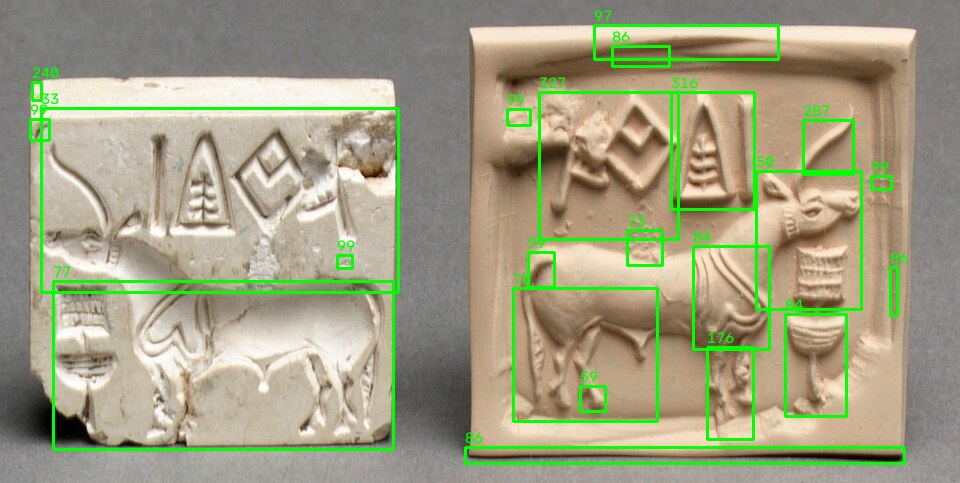

**met_cropped_rtdetr-l**

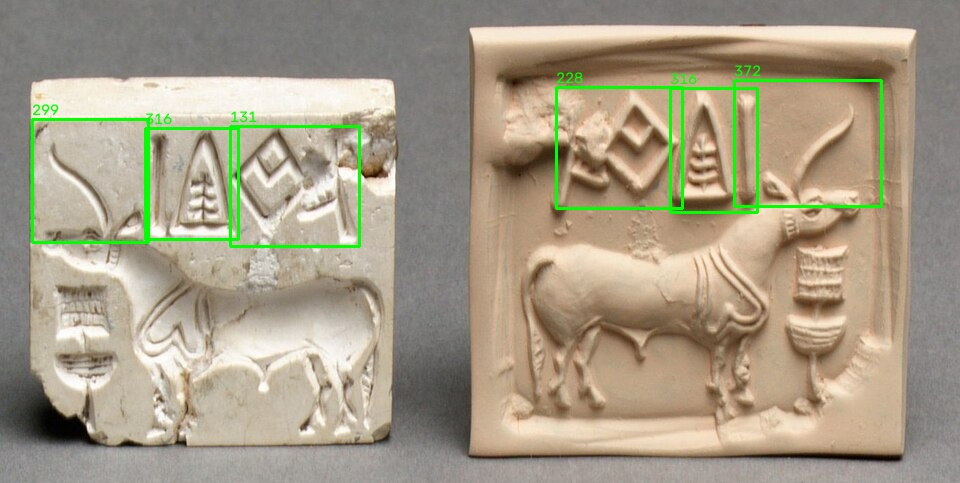

**met_cropped_yolov8n**

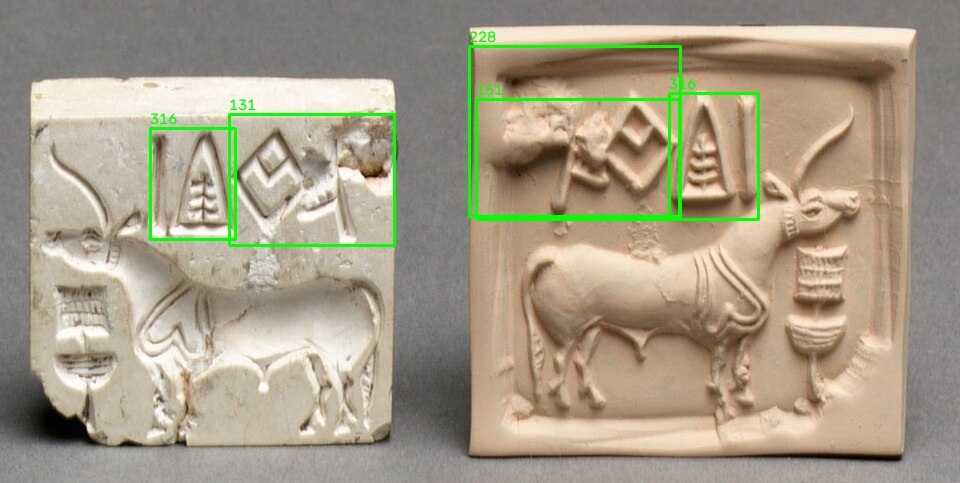

**met_detail_opencv**

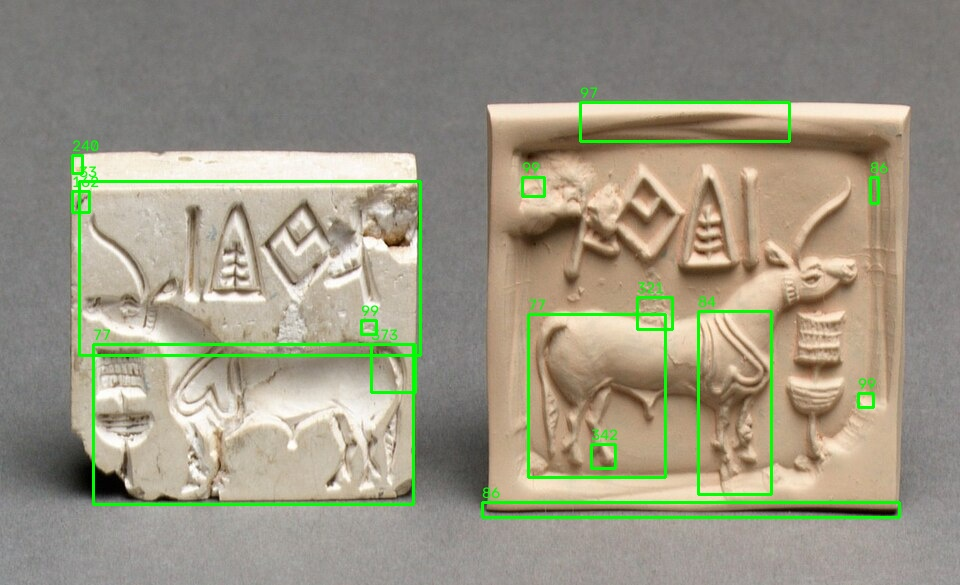

**met_detail_rtdetr-l**

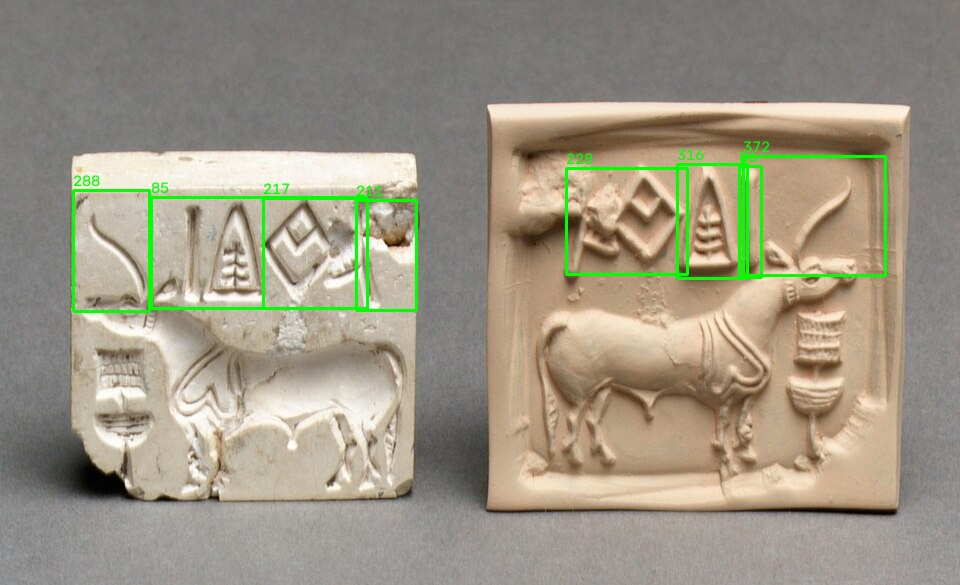

**met_detail_yolov8n**

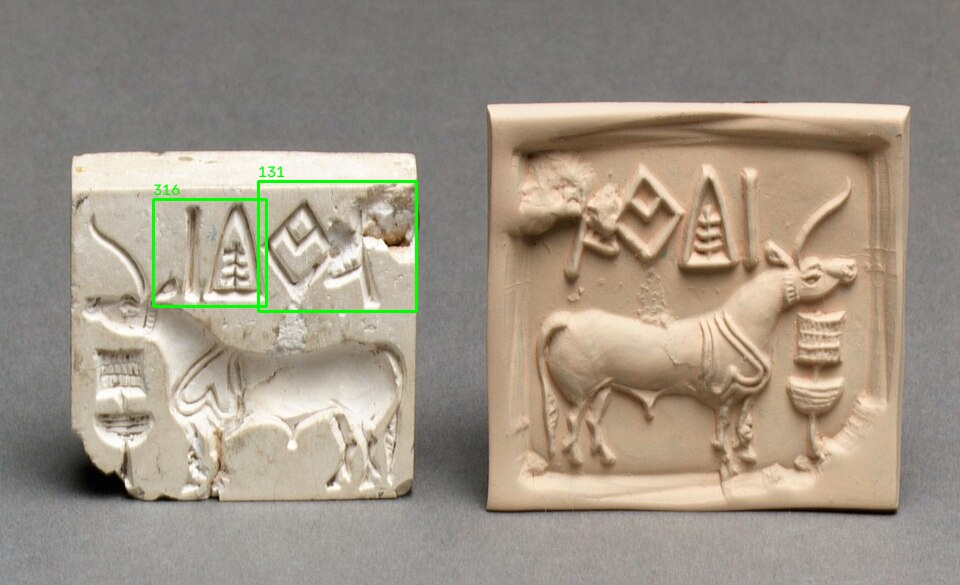

In [6]:
for f in sorted((R / 'figures').glob('*.jpg')):
    display(Markdown(f'**{f.stem}**'), Image(str(f), width=700))